# Autostep in a network: keeping distractor connections quiet

A two-layer LTU network is trained with Autostep after we wire in connections we know are useless
(*distractors*). We want Autostep to leave them alone: their step-sizes should shrink over learning and their
weights should stay near 0, at no cost in loss.

**Problem.** Stationary 2-task simple multi-GEOFF. Each task is an independent teacher network with 21 inputs,
10 zero-threshold LTUs and 10 linear outputs, with $N(0, 1)$ noise added to each output. The inputs and every teacher
weight are random $\pm 1$ signs, so each LTU fires with probability 1/2 and each output's signal has variance about
2.5. The targets have a nonzero mean. Training is online, one fresh sample per step.

**Network.** 42 inputs → 20 LTU hidden units (10 per task) → 20 linear outputs. An LTU is a step function forward and
a sigmoid derivative backward. Each layer has a bias, a constant-1 input. The connectivity is fixed: every hidden
unit reads all of its own task's inputs and feeds all of its own task's outputs. On top of that comes one kind of
distractor, each in its own problem: in the **output-distractor problem**, even hidden units also feed all of the
other task's outputs (100 distractors); in the **input-distractor problem**, odd hidden units also read all of the
other task's inputs (210 distractors). The two kinds are kept apart because, together, each can learn to cancel the
cross-task noise the other injects, so neither would be useless. Question 3 puts them back together, once both fixes
keep them near 0.

**Learner.** Autostep, treating each layer as its own linear problem (each weight is normalized by the squared value
of its source unit), on the loss $\frac{1}{2}\|\hat{y} - y\|^2$. Every step-size starts at $10^{-8}$. Input weights
start LeCun uniform; output weights and biases start at 0.

**What we look at**, over 30 seeds: the RMSE over outputs (its minimum, the noise, is 1), as a learning curve with
$\pm 2$ standard errors and over the last 10% of training against the baseline's; and, pooled over the distractors a
section is about, the mean and 90th percentile of $\beta = \ln(\alpha)$, the log step-size, and the median and 90th
percentile of $|w|$ (the plots show the 90th percentiles only when `SHOW_P90` is on). The mean is taken over
$\beta$, not $\alpha$, so step-sizes that merely spread out symmetrically do not count as a rise.

Everything is recorded at step 1, then averaged over each window of 4000 steps.

In [1]:
from typing import NamedTuple

import equinox as eqx
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

from phd.jax_core.models import ltu
from phd.jax_core.optimizers.idbd import IDBDState, optax_idbd
from phd.jax_core.tasks.simple_multi_geoff import SimpleMultiGEOFFTask
from phd.jax_core.utils import stack_pytrees

sns.set_theme('notebook', 'whitegrid')
%matplotlib inline

/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an 

In [2]:
# --- Problem ---
N_TASKS = 2
N_INPUTS_PER_TASK = 21
N_TEACHER_LTUS_PER_TASK = 10
N_OUTPUTS_PER_TASK = 10
NOISE_STD = 1.0

# --- Network ---
N_HIDDEN_PER_TASK = 10

# --- Autostep ---
INIT_STEP_SIZE = 1e-8
META_STEP_SIZE = 0.02
TAU = 1e4

# --- Sweeps ---
BIAS_STEP_SIZES = (2 ** -6, 2 ** -4, 2 ** -2)
EMA_RATES = (1e-2, 1e-3, 1e-4)

# --- Training ---
NUM_STEPS = 1_000_000
N_SEEDS = 30
N_WINDOWS = 250                      # each window records the mean of the loss and of every recorded beta and |w|

# --- Results ---
FINAL_FRACTION = 0.1                 # the loss is compared over the last 10% of training
SHOW_P90 = False                     # also plot the distractors' 90th percentile of beta and |w|

In [3]:
LAYERS = ('w1', 'w2')
N_HIDDEN = N_TASKS * N_HIDDEN_PER_TASK
N_OUTPUTS = N_TASKS * N_OUTPUTS_PER_TASK

input_task = np.repeat(np.arange(N_TASKS), N_INPUTS_PER_TASK)
hidden_task = np.repeat(np.arange(N_TASKS), N_HIDDEN_PER_TASK)
output_task = np.repeat(np.arange(N_TASKS), N_OUTPUTS_PER_TASK)
reads_other_inputs = np.arange(N_HIDDEN) % 2 == 1        # odd hidden units
feeds_other_outputs = ~reads_other_inputs                 # even hidden units


def with_bias_column(mask, bias):
    # The last column of each weight matrix reads the constant-1 input.
    return np.concatenate([mask, np.full((mask.shape[0], 1), bias)], axis=1)


# Masks are shaped like the weight matrices: w1 is (hidden, inputs + 1), w2 is (outputs, hidden + 1).
same_task = {'w1': hidden_task[:, None] == input_task[None, :],
             'w2': output_task[:, None] == hidden_task[None, :]}
DISTRACTORS = {'w1': with_bias_column(~same_task['w1'] & reads_other_inputs[:, None], False),
               'w2': with_bias_column(~same_task['w2'] & feeds_other_outputs[None, :], False)}
BLOCK_SPARSE = {k: with_bias_column(m, True) for k, m in same_task.items()}
USEFUL = {k: with_bias_column(m, False) for k, m in same_task.items()}     # BLOCK_SPARSE without the biases

# Each problem is block-sparse plus one kind of distractor ('both' has both, for Question 3); 'none' has none.
DISTRACTOR_LAYER = {'output': 'w2', 'input': 'w1'}
MASKS = {'none': BLOCK_SPARSE,
         'output': {'w1': BLOCK_SPARSE['w1'], 'w2': BLOCK_SPARSE['w2'] | DISTRACTORS['w2']},
         'input': {'w1': BLOCK_SPARSE['w1'] | DISTRACTORS['w1'], 'w2': BLOCK_SPARSE['w2']},
         'both': {k: BLOCK_SPARSE[k] | DISTRACTORS[k] for k in LAYERS}}
PROBLEM_NAMES = {'output': 'Output Distractor Problem', 'input': 'Input Distractor Problem',
                 'both': 'Output + Input Distractor Problem'}

for k in LAYERS:
    print(f'{k}: {BLOCK_SPARSE[k][:, :-1].sum()} useful, {DISTRACTORS[k].sum()} distractors, '
          f'{BLOCK_SPARSE[k].shape[0]} biases')

w1: 420 useful, 210 distractors, 20 biases
w2: 200 useful, 100 distractors, 20 biases


## Learner

In [4]:
OPTIMIZER = optax_idbd(meta_lr=META_STEP_SIZE, init_lr=INIT_STEP_SIZE, autostep=True, tau=TAU,
                       version='squared_inputs')


class Method(eqx.Module):
    # What differs between runs. The float fields can be swept (they are vmapped); the rest are fixed per run.
    problem: str = eqx.field(static=True)                       # which distractors the network has: a key of MASKS
    bias_step_size: float = INIT_STEP_SIZE                      # initial step-size of every bias
    ema_rate: float = 1e-3                                      # rate of the hidden units' running means
    centered: bool = eqx.field(static=True, default=False)      # send h - m, with the gradient of h - E[h]
    kappa: float = 0.0                                          # step-size decay (Question 4): every beta also falls by META_STEP_SIZE * kappa per step
    w1_init: str = eqx.field(static=True, default='lecun')      # 'lecun', or 'step_size' for U(-INIT_STEP_SIZE, INIT_STEP_SIZE)

    @property
    def masks(self):
        return MASKS[self.problem]


class Learner(NamedTuple):
    w: dict                   # {'w1': ..., 'w2': ...}; masked-out weights stay at exactly 0 (their gradient is 0)
    opt: IDBDState
    hidden_mean: jax.Array    # each hidden unit's running mean; every run tracks it, but only centering uses it
    hidden_slope: jax.Array   # running mean of sigma'(z) x, each hidden unit's derivative w.r.t. each input weight;
                              # only centering uses it


def init_learner(method, key):
    masks = method.masks
    # Input weights: LeCun uniform over each unit's inputs, or uniform on +-INIT_STEP_SIZE. Both scale the same draw.
    fan_in = masks['w1'][:, :-1].sum(1, keepdims=True)
    bound = INIT_STEP_SIZE if method.w1_init == 'step_size' else np.sqrt(3.0 / fan_in)
    w1 = jax.random.uniform(key, masks['w1'].shape, minval=-1.0, maxval=1.0) * bound * masks['w1']
    w = {'w1': w1.at[:, -1].set(0.0), 'w2': jnp.zeros(masks['w2'].shape)}

    opt = OPTIMIZER.init(w)
    opt = opt._replace(beta={k: b.at[:, -1].set(jnp.log(method.bias_step_size)) for k, b in opt.beta.items()})
    # A zero-threshold LTU with symmetric inputs fires with probability 1/2, so these start out exact. The slope starts
    # at sigma'(0) E[x]: 0 for the zero-mean inputs, 1/4 for the bias.
    return Learner(w, opt, jnp.full(N_HIDDEN, 0.5), jnp.zeros(masks['w1'].shape).at[:, -1].set(0.25))


def forward(w, x, learner, method):
    # Returns the prediction, each weight's source values (what Autostep normalizes by), and the new running means.
    masks = method.masks
    x = jnp.append(x, 1.0)
    w1 = w['w1'] * masks['w1']
    z = w1 @ x
    h = ltu(z)

    # Running means, updated with this sample before they are used. No gradient flows through them.
    mean = learner.hidden_mean + method.ema_rate * (jax.lax.stop_gradient(h) - learner.hidden_mean)
    sigma_prime = jax.lax.stop_gradient(jax.nn.sigmoid(z) * (1.0 - jax.nn.sigmoid(z)))     # the LTU's surrogate slope
    slope = learner.hidden_slope + method.ema_rate * (sigma_prime[:, None] * x[None, :] - learner.hidden_slope)
    if method.centered:
        # Send h - m, with the gradient of h - E[h]: each input weight's derivative becomes sigma'(z) x - slope. The
        # correction leaves the value unchanged.
        correction = jnp.sum(slope * w1, axis=1)
        h = h - mean - correction + jax.lax.stop_gradient(correction)

    h = jnp.append(h, 1.0)
    y_hat = (w['w2'] * masks['w2']) @ h
    return y_hat, ({'w1': x[None], 'w2': h[None]}, mean, slope)


def learner_step(learner, x, y, method):
    # One online Autostep update. Returns the new learner and the squared error summed over outputs.
    def loss_fn(w):
        y_hat, aux = forward(w, x, learner, method)
        return 0.5 * jnp.sum((y_hat - y) ** 2), aux

    (loss, (source_values, mean, slope)), grads = jax.value_and_grad(loss_fn, has_aux=True)(learner.w)
    updates, opt = OPTIMIZER.update((grads, None, source_values), learner.opt, learner.w)
    opt = opt._replace(beta={k: b - META_STEP_SIZE * method.kappa for k, b in opt.beta.items()})   # decay, from the next step
    w = {k: learner.w[k] + updates[k] for k in LAYERS}
    return Learner(w, opt, mean, slope), 2.0 * loss

## Training

In [5]:
WINDOW = NUM_STEPS // N_WINDOWS


def recorded_values(learner, record):
    # beta and |w| of the weights in `record` (a mask per layer), flattened per layer.
    return {k: {'beta': learner.opt.beta[k][record[k]],
                'w': jnp.abs(learner.w[k])[record[k]]} for k in LAYERS}


def train(method, key, task, record):
    # Step 1 on its own, then NUM_STEPS online steps in windows. Returns the per-output MSE, and the beta (log
    # step-size) and |w| of each weight in `record`: at step 1, then averaged over every window.
    def one_step(carry, _):
        learner, task, total = carry
        task, (x, y) = task.generate_batch(1)
        learner, sq_err = learner_step(learner, x[0], y[0], method)
        total = jax.tree.map(jnp.add, total, recorded_values(learner, record))
        return (learner, task, total), sq_err

    def window(carry, _):
        learner, task = carry
        zeros = jax.tree.map(jnp.zeros_like, recorded_values(learner, record))
        (learner, task, total), sq_err = jax.lax.scan(one_step, (learner, task, zeros), length=WINDOW)
        return (learner, task), (sq_err.mean() / N_OUTPUTS, jax.tree.map(lambda t: t / WINDOW, total))

    task, (x, y) = task.generate_batch(1)
    learner, sq_err = learner_step(init_learner(method, key), x[0], y[0], method)
    _, (mse, values) = jax.lax.scan(window, (learner, task), length=N_WINDOWS)
    first = (sq_err / N_OUTPUTS, recorded_values(learner, record))
    return jax.tree.map(lambda f, v: jnp.concatenate([f[None], v]), first, (mse, values))


def seeds():
    # Init keys and teachers. Seed s uses teacher s and init key s for every method, so runs are paired.
    tasks = stack_pytrees([
        SimpleMultiGEOFFTask(N_TASKS, n_features_per_task=N_INPUTS_PER_TASK,
                             n_hidden_per_task=N_TEACHER_LTUS_PER_TASK, n_outputs_per_task=N_OUTPUTS_PER_TASK,
                             noise_std=NOISE_STD, seed=s)
        for s in range(N_SEEDS)])
    return jax.random.split(jax.random.PRNGKey(0), N_SEEDS), tasks


def run(methods, record=DISTRACTORS):
    # Train every method in `methods` ({label: Method}, all with the same static fields) on the same N_SEEDS seeds,
    # vmapped into one scan, recording the weights in `record`.
    keys, tasks = seeds()
    over_seeds = jax.vmap(lambda method, key, task: train(method, key, task, record), in_axes=(None, 0, 0))
    mse, values = jax.jit(jax.vmap(over_seeds, in_axes=(0, None, None)))(
        stack_pytrees(list(methods.values())), keys, tasks)
    # Per run: RMSE (seed, step 1 + window), and values[layer][quantity] (seed, step 1 + window, recorded weight).
    return {label: {'rmse': np.sqrt(np.asarray(mse[i])),
                    **{k: {q: np.asarray(v[i]) for q, v in values[k].items()} for k in LAYERS}}
            for i, label in enumerate(methods)}

## Plots

In [6]:
STEPS = 1 + np.arange(N_WINDOWS + 1) * WINDOW     # step 1, then the end of every window


def colors(runs):
    # The baseline in red, the references in gray, and the proposed methods in shades of blue.
    fixed = {'baseline': 'tab:red', 'no distractors': 'gray', 'no decay': 'gray'}
    methods = [label for label in runs if label not in fixed]
    shades = dict(zip(methods, plt.cm.Blues(np.linspace(0.9, 0.5, len(methods)))))
    return [{**fixed, **shades}[label] for label in runs]


def pooled(values, center):
    # `center` (np.mean or np.median) and the 90th percentile per window, over every distractor of every seed. `values`
    # is (seed, window, distractor).
    v = values.transpose(1, 0, 2).reshape(values.shape[1], -1)
    return center(v, axis=1), np.percentile(v, 90, axis=1)


def plot_loss(runs, problem):
    plt.figure(figsize=(7, 4))
    for (label, res), color in zip(runs.items(), colors(runs)):
        mean = res['rmse'].mean(0)
        sem = res['rmse'].std(0) / np.sqrt(N_SEEDS)
        plt.plot(STEPS, mean, color=color, lw=1.5, label=label)
        plt.fill_between(STEPS, mean - 2 * sem, mean + 2 * sem, color=color, alpha=0.2)
    plt.axhline(NOISE_STD, color='black', lw=1.5, ls=':', label='minimum')
    plt.xlabel('step')
    plt.ylabel('RMSE')
    plt.title(f'Learning Curve | {PROBLEM_NAMES[problem]}')
    plt.legend(fontsize=8)
    plt.tight_layout()
    plt.show()


def plot_distractors(runs, kind, problem=None):
    # The `kind` ('output' or 'input') distractors on `problem`, by default the problem with only that kind.
    layer = DISTRACTOR_LAYER[kind]
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    # Each panel: quantity, y label, central statistic (the mean of beta, a log, sits mid-distribution; the median of
    # |w| does too, where its mean would be pulled up by the largest weights), y scale, and the lowest value shown (an
    # order of magnitude below the initial step-size; anything smaller is just "small").
    panels = [('beta', '$\\beta = \\ln(\\alpha)$', ('mean', np.mean), 'linear', np.log(INIT_STEP_SIZE / 10)),
              ('w', '$|w|$', ('median', np.median), 'log', INIT_STEP_SIZE / 10)]
    axes[0].axhline(np.log(INIT_STEP_SIZE), color='black', lw=1.5, label='initial $\\beta$')
    for ax, (quantity, ylabel, (center_name, center), yscale, bottom) in zip(axes, panels):
        for (label, res), color in zip(runs.items(), colors(runs)):
            mid, p90 = (np.maximum(s, bottom) for s in pooled(res[layer][quantity], center))   # drawn on the floor once below it
            ax.plot(STEPS, mid, color=color, lw=1.5, label=label)
            if SHOW_P90:
                ax.plot(STEPS, p90, color=color, lw=1.5, ls='--')
        if SHOW_P90:
            ax.plot([], [], color='gray', lw=1.5, label=center_name)
            ax.plot([], [], color='gray', lw=1.5, ls='--', label='90th percentile')
        ax.set_yscale(yscale)
        ax.set_ylim(bottom=bottom)
        ax.set_xlabel('step')
        ax.set_ylabel(ylabel if SHOW_P90 else f'{center_name} {ylabel}')
        ax.legend(fontsize=8)
    fig.suptitle(f'{kind.capitalize()} Distractors Over Learning | {PROBLEM_NAMES[problem or kind]}')
    fig.tight_layout()
    plt.show()


def report(runs, kind):
    # The RMSE over the last FINAL_FRACTION of training (against runs['baseline']), and on the `kind` ('output' or
    # 'input') distractors, |w| at its worst window and beta (log step-size) in the last window.
    layer = DISTRACTOR_LAYER[kind]
    final = slice(-round(N_WINDOWS * FINAL_FRACTION), None)
    baseline_rmse = runs['baseline']['rmse'][:, final].mean()
    width = max(map(len, runs))
    print(f'{kind} distractors (initial beta {np.log(INIT_STEP_SIZE):.1f})')
    for label, res in runs.items():
        rmse = res['rmse'][:, final].mean()
        w_median, w_p90 = (s.max() for s in pooled(res[layer]['w'], np.median))
        b_mean, b_p90 = (s[-1] for s in pooled(res[layer]['beta'], np.mean))
        print(f'  {label:<{width}}   RMSE {rmse:.3f} ({rmse - baseline_rmse:+.3f})   '
              f'max |w|: median {w_median:.1e}, p90 {w_p90:.1e}   final beta: mean {b_mean:.1f}, p90 {b_p90:.1f}')

## Baseline

Standard Autostep as described at the top, on each problem. The *no distractors* reference is the same network
without any distractors: the loss we would get if they cost nothing.

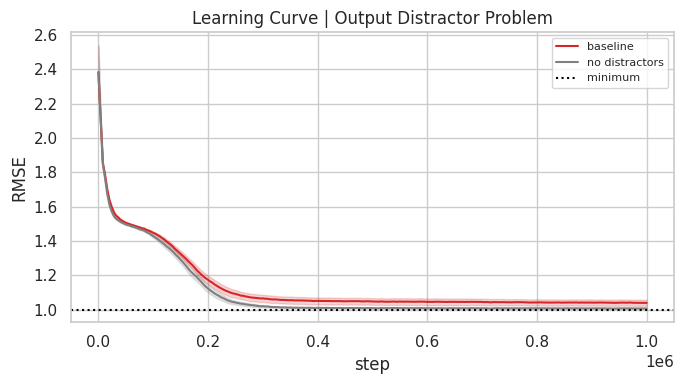

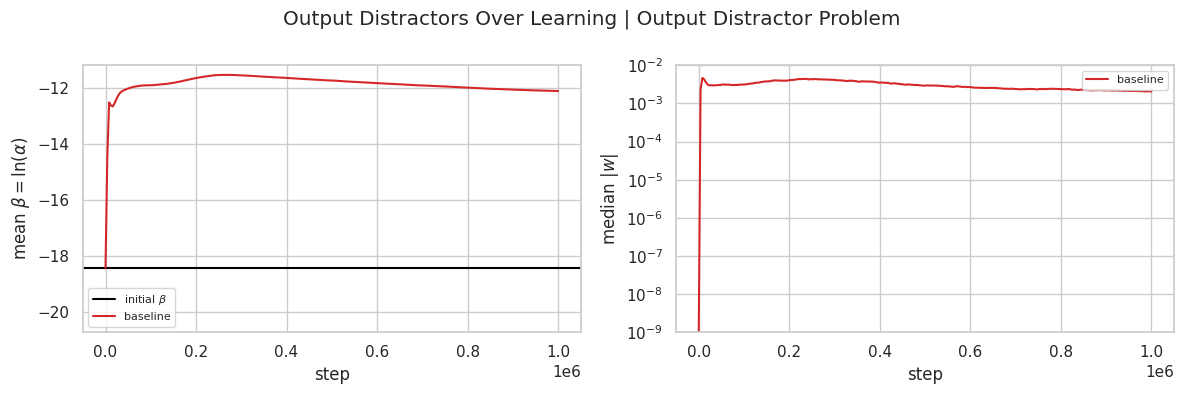

output distractors (initial beta -18.4)
  baseline   RMSE 1.040 (+0.000)   max |w|: median 4.7e-03, p90 2.2e-02   final beta: mean -12.1, p90 -10.4


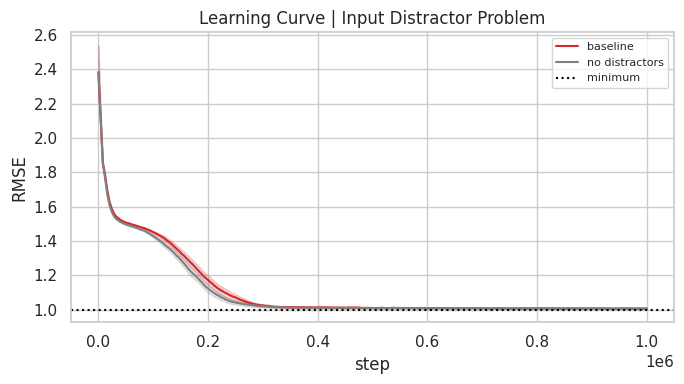

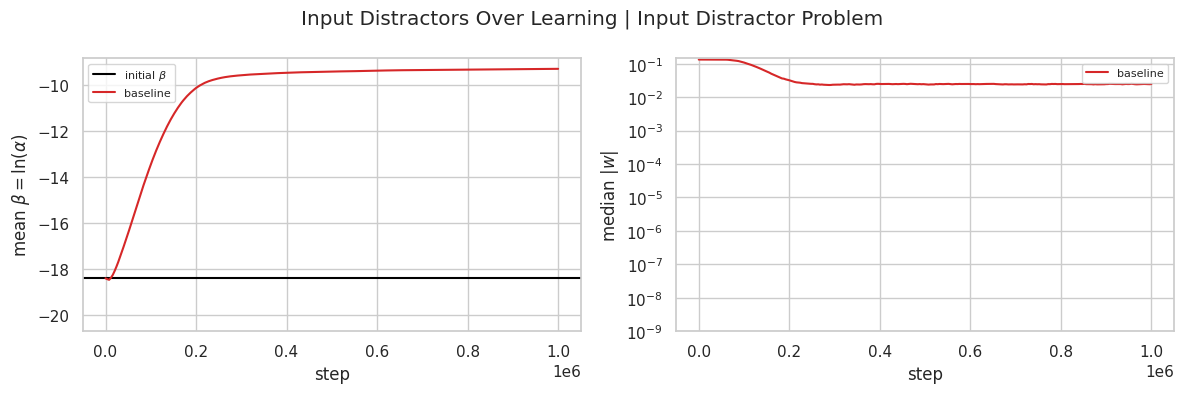

input distractors (initial beta -18.4)
  baseline   RMSE 1.006 (+0.000)   max |w|: median 1.3e-01, p90 2.4e-01   final beta: mean -9.3, p90 -7.1


In [7]:
baseline = {problem: run({'baseline': Method(problem=problem)})['baseline'] for problem in DISTRACTOR_LAYER}
reference = run({'no distractors': Method(problem='none')})

for problem in DISTRACTOR_LAYER:
    plot_loss({'baseline': baseline[problem], **reference}, problem)
    plot_distractors({'baseline': baseline[problem]}, problem)
    report({'baseline': baseline[problem]}, problem)

## Question 1: distractors from non-zero-mean hidden units acting as biases

An LTU outputs 0 or 1, so every hidden unit has a positive mean. While an output still has a mean error, an
output distractor gets a consistently signed gradient and acts as a partial bias: its weight and step-size grow,
and take a long time to come back down. Each method below is compared with the baseline on the
**output-distractor problem**.

### 1a. Fast biases

The biases of both layers start at a much larger step-size than every other weight, so they can absorb the
targets' mean before the distractors do.

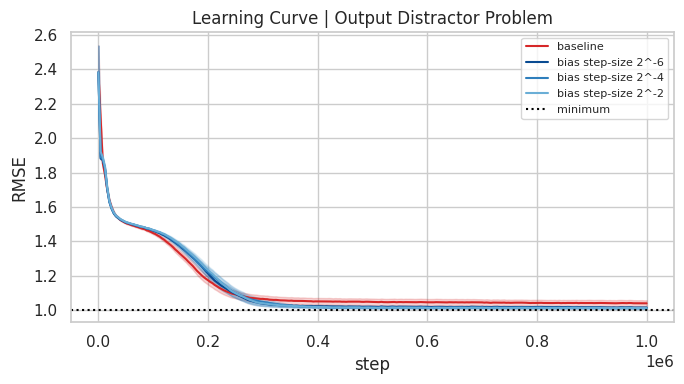

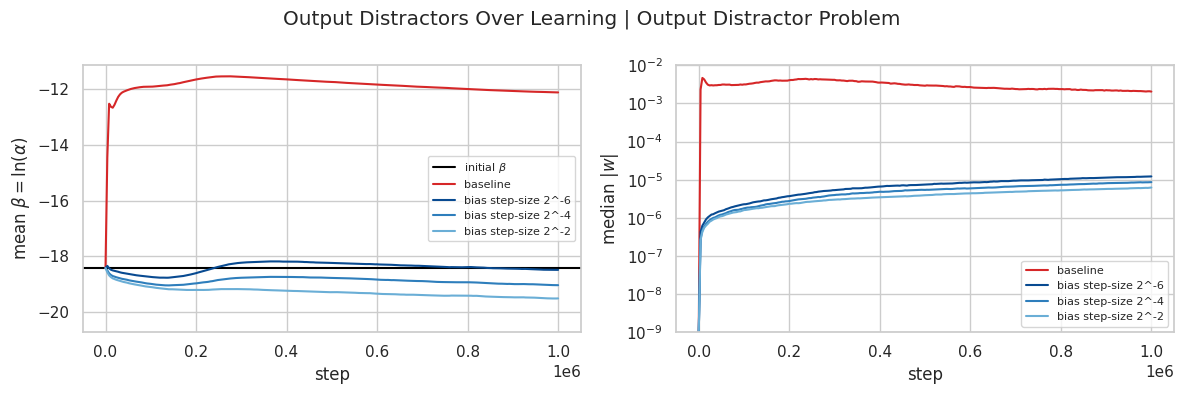

output distractors (initial beta -18.4)
  baseline              RMSE 1.040 (+0.000)   max |w|: median 4.7e-03, p90 2.2e-02   final beta: mean -12.1, p90 -10.4
  bias step-size 2^-6   RMSE 1.015 (-0.025)   max |w|: median 1.2e-05, p90 5.3e-04   final beta: mean -18.5, p90 -14.8
  bias step-size 2^-4   RMSE 1.013 (-0.028)   max |w|: median 8.6e-06, p90 1.9e-04   final beta: mean -19.0, p90 -15.8
  bias step-size 2^-2   RMSE 1.012 (-0.028)   max |w|: median 6.2e-06, p90 6.5e-05   final beta: mean -19.5, p90 -16.8


In [8]:
fast_bias = run({f'bias step-size 2^{np.log2(a):.0f}': Method(problem='output', bias_step_size=a)
                 for a in BIAS_STEP_SIZES})

runs = {'baseline': baseline['output'], **fast_bias}
plot_loss(runs, 'output')
plot_distractors(runs, 'output')
report(runs, 'output')

### 1b. Centering

Each hidden unit sends $h - m$ instead of $h$, where $m$ is its running mean firing rate (an exponential moving average
starting at $m = 1/2$, at the rate in the legend). The backward pass matches: it takes the gradient of
$h - \mathbb{E}[h]$, so the derivative with respect to input weight $k$ is $\sigma'(z)\,x_k - s_k$, where $s_k$ is a
running mean of $\sigma'(z)\,x_k$ at the same rate (starting at $\sigma'(0)\,\mathbb{E}[x_k]$: 0 for the inputs, 1/4
for the bias).

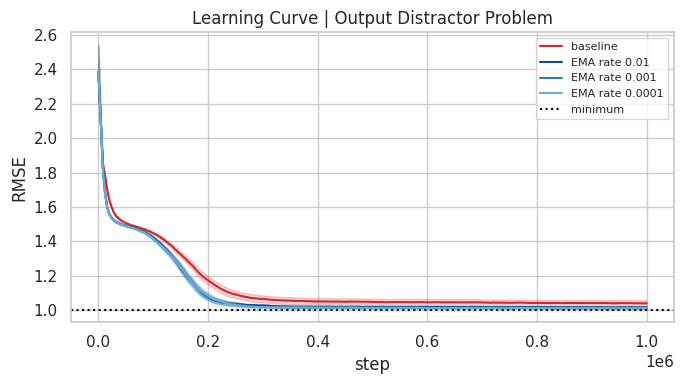

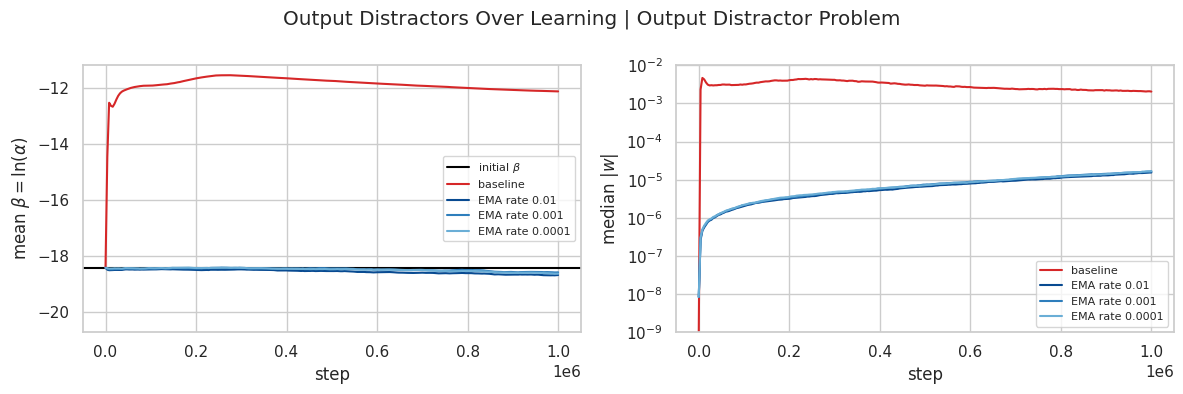

output distractors (initial beta -18.4)
  baseline          RMSE 1.040 (+0.000)   max |w|: median 4.7e-03, p90 2.2e-02   final beta: mean -12.1, p90 -10.4
  EMA rate 0.01     RMSE 1.016 (-0.024)   max |w|: median 1.5e-05, p90 5.4e-04   final beta: mean -18.7, p90 -14.3
  EMA rate 0.001    RMSE 1.011 (-0.030)   max |w|: median 1.7e-05, p90 6.3e-04   final beta: mean -18.6, p90 -14.1
  EMA rate 0.0001   RMSE 1.011 (-0.029)   max |w|: median 1.7e-05, p90 6.7e-04   final beta: mean -18.6, p90 -14.0


In [9]:
centered = run({f'EMA rate {r:g}': Method(problem='output', centered=True, ema_rate=r) for r in EMA_RATES})

runs = {'baseline': baseline['output'], **centered}
plot_loss(runs, 'output')
plot_distractors(runs, 'output')
report(runs, 'output')

## Question 2: input weights initialized off zero

With the usual fan-in initialization, an input distractor starts far from 0, so its gradient pulls it toward 0
consistently, and its step-size spikes until it gets there. Here the input weights are instead drawn from
U(−α₀, α₀), where α₀ = 10⁻⁸ is the initial step-size. The draw is the baseline's, only rescaled, so the hidden
units compute exactly the same features at step 0. Compared with the baseline on the **input-distractor problem**.

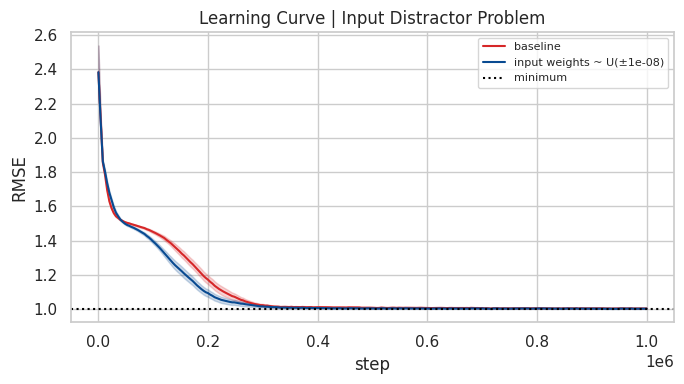

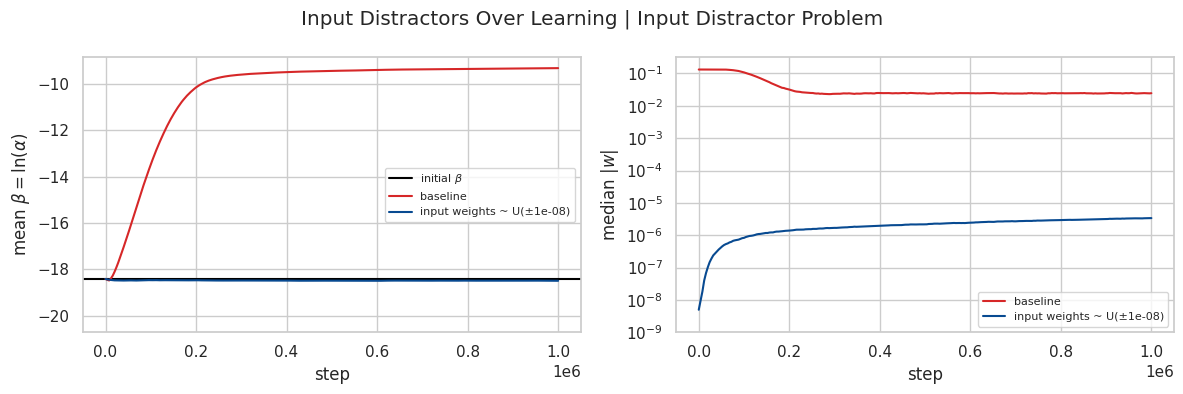

input distractors (initial beta -18.4)
  baseline                    RMSE 1.006 (+0.000)   max |w|: median 1.3e-01, p90 2.4e-01   final beta: mean -9.3, p90 -7.1
  input weights ~ U(±1e-08)   RMSE 1.004 (-0.002)   max |w|: median 3.4e-06, p90 4.0e-05   final beta: mean -18.5, p90 -16.2


In [10]:
small_init = run({f'input weights ~ U(±{INIT_STEP_SIZE:g})': Method(problem='input', w1_init='step_size')})

runs = {'baseline': baseline['input'], **small_init}
plot_loss(runs, 'input')
plot_distractors(runs, 'input')
report(runs, 'input')

## Question 3: fixing the whole network at once

Questions 1 and 2 each fixed one layer on its own problem: centering the hidden units kept the output distractors'
step-sizes from rising (1b), and starting the input weights at U(−α₀, α₀) kept the input distractors' step-sizes from
spiking (Question 2). If both fixes carry over, using them together on the problem with both kinds of distractor should
keep every distractor quiet. Biases start at α₀, like every other weight.

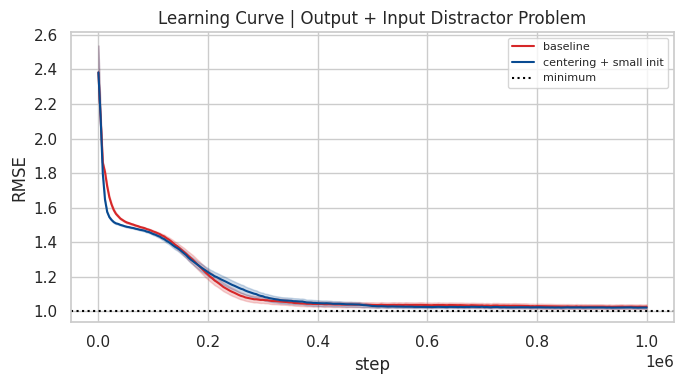

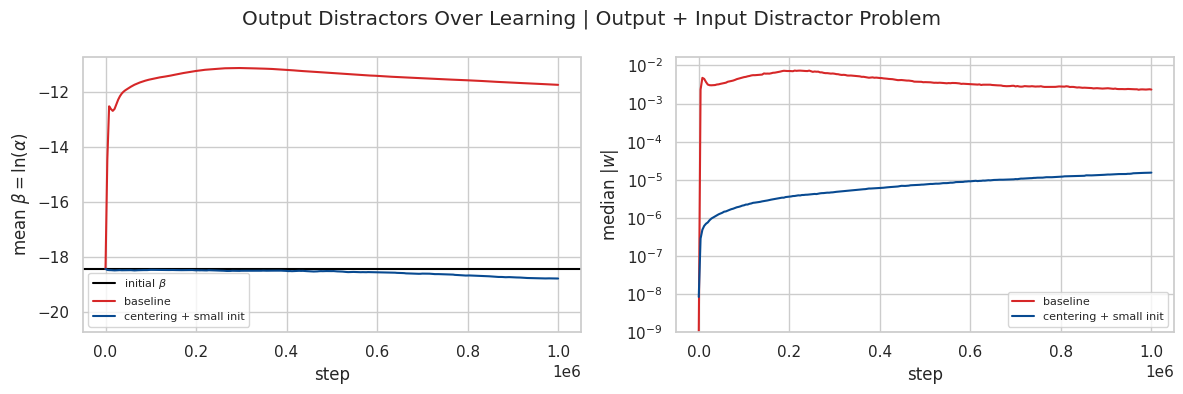

output distractors (initial beta -18.4)
  baseline                 RMSE 1.028 (+0.000)   max |w|: median 7.3e-03, p90 3.4e-02   final beta: mean -11.7, p90 -10.1
  centering + small init   RMSE 1.022 (-0.005)   max |w|: median 1.5e-05, p90 6.5e-04   final beta: mean -18.8, p90 -14.3


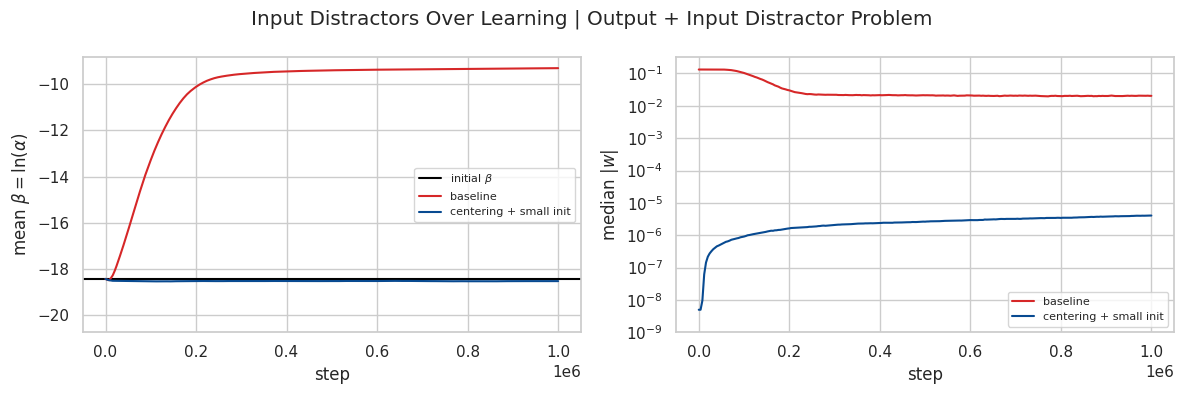

input distractors (initial beta -18.4)
  baseline                 RMSE 1.028 (+0.000)   max |w|: median 1.3e-01, p90 2.4e-01   final beta: mean -9.3, p90 -7.2
  centering + small init   RMSE 1.022 (-0.005)   max |w|: median 4.1e-06, p90 5.3e-05   final beta: mean -18.5, p90 -16.0


In [11]:
combination = dict(problem='both', centered=True, w1_init='step_size')
both_baseline = run({'baseline': Method(problem='both')})
both_combination = run({'centering + small init': Method(**combination)})

runs = {**both_baseline, **both_combination}
plot_loss(runs, 'both')
for kind in DISTRACTOR_LAYER:
    plot_distractors(runs, kind, 'both')
    report(runs, kind)

## Distractors against useful weights

The Question 3 network (centering and small input weights) on the problem with both kinds of distractor. In each layer, its distractors are compared with its useful connections (the block structure, without
biases): the mean of $\beta$ and the median of $|w|$, with the 5th to 95th percentile shaded, pooled over seeds.

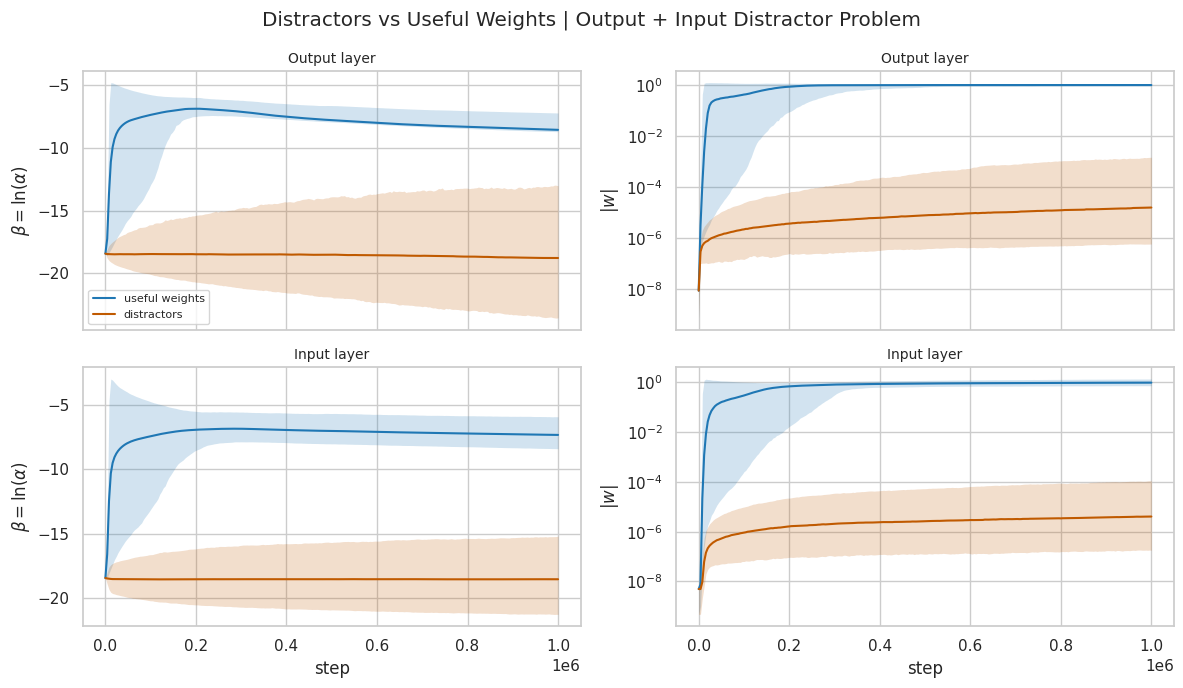

In [12]:
# Question 3's run again, recording its useful weights.
useful_run = run({'useful': Method(**combination)}, record=USEFUL)['useful']
groups = {'useful weights': useful_run, 'distractors': both_combination['centering + small init']}

fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
columns = [('beta', '$\\beta = \\ln(\\alpha)$', np.mean, 'linear'), ('w', '$|w|$', np.median, 'log')]
for row, (kind, layer) in zip(axes, DISTRACTOR_LAYER.items()):
    for ax, (quantity, ylabel, center, yscale) in zip(row, columns):
        for (label, res), color in zip(groups.items(), ('#1f77b4', '#c05a00')):
            v = res[layer][quantity].transpose(1, 0, 2).reshape(len(STEPS), -1)     # (step, weight of any seed)
            ax.plot(STEPS, center(v, axis=1), color=color, lw=1.5, label=label)
            ax.fill_between(STEPS, *np.percentile(v, [5, 95], axis=1), color=color, alpha=0.2, lw=0)
        ax.set_yscale(yscale)
        ax.set_title(f'{kind.capitalize()} layer', fontsize=10)
        ax.set_ylabel(ylabel)
for ax in axes[1]:
    ax.set_xlabel('step')
axes[0, 0].legend(fontsize=8)
fig.suptitle(f'Distractors vs Useful Weights | {PROBLEM_NAMES["both"]}')
fig.tight_layout()
plt.show()

<!-- PARKED (Question 4): remove this comment wrapper to show the text.
## Question 4: making every distractor's step-size fall

With centering and small input weights (Question 3), the output distractors' mean $\beta$ falls, but their 90th
percentile stays above the initial $\beta$, and the input distractors' mean $\beta$ does not fall at all. Each step
moves a distractor's $\beta$ by $\mu\,hg/v$, a random step of fixed size (about $\pm 0.17\mu$) however small its
step-size. The only pull down comes from
the distractor's own effect on the error, which is proportional to its $|w|$ and too weak to win within 1M steps. An
input distractor has no pull at all, since a tiny input weight almost never flips its LTU. So the spread of $\beta$
keeps growing, and as a few large step-sizes dominate their average, the mean step-size rises even where the mean of
$\beta$ falls.

How can we make every distractor's step-size fall: its mean, and, given enough time, every percentile?
-->

In [13]:
# PARKED, NOT RUN (Question 4, step-size decay): uncomment this cell and the rest of Question 4 to run it.
# def plot_step_sizes(runs, kind):
#     # The mean of beta next to the mean step-size (the mean of exp(beta)), averaged over each window, pooled over every
#     # distractor of every seed. Anything more than an order of magnitude below the initial step-size is drawn on the floor.
#     layer = DISTRACTOR_LAYER[kind]
#     fig, axes = plt.subplots(1, 2, figsize=(12, 4))
#     panels = [(lambda b: b, 'mean $\\beta$', np.log(INIT_STEP_SIZE), 'initial $\\beta$', 'linear',
#                np.log(INIT_STEP_SIZE / 10)),
#               (np.exp, 'mean step-size', INIT_STEP_SIZE, 'initial step-size', 'log', INIT_STEP_SIZE / 10)]
#     for ax, (transform, ylabel, ref, ref_label, yscale, bottom) in zip(axes, panels):
#         for (label, res), color in zip(runs.items(), colors(runs)):
#             mean = transform(res[layer]['beta']).mean(axis=(0, 2))
#             ax.plot(STEPS, np.maximum(mean, bottom), color=color, lw=1.5, label=label)
#         ax.axhline(ref, color='black', lw=1.5, label=ref_label)
#         ax.set_yscale(yscale)
#         ax.set_ylim(bottom=bottom)
#         ax.set_xlabel('step')
#         ax.set_ylabel(ylabel)
#         ax.grid(alpha=0.4, which='both')
#         ax.legend(fontsize=8)
#     fig.suptitle(f'{kind.capitalize()} distractors (averaged over each window; pooled over seeds)')
#     fig.tight_layout()
#     plt.show()
#
#
# no_decay = {'no decay': both_combination['centering + small init']}
# for kind in DISTRACTOR_LAYER:
#     plot_step_sizes(no_decay, kind)

<!-- PARKED (Question 4): remove this comment wrapper to show the text.
### 4b. Step-size decay

Every $\beta$ also falls by $\mu\kappa$ per step, so $\beta \leftarrow \beta + \mu\,(hg/v - \kappa)$: a step-size grows
only while its weight's mean $hg/v$ exceeds $\kappa$. This gives every distractor the same steady pull down, which grows
linearly in time while the spread of $\beta$ grows only as its square root, so given enough time every percentile falls;
$\kappa$ sets how soon. The decay applies to every weight, so it also lowers the useful weights' step-sizes once their
mean $hg/v$ drops below $\kappa$. In Question 3's network that happens after about 100k steps, when the network has
mostly learned and their mean $hg/v$ is about 0. Built on Question 3's network (labelled "no decay"), with
$\kappa \in \{10^{-3}, 10^{-4}, 10^{-5}\}$.
-->

In [14]:
# PARKED, NOT RUN (Question 4, step-size decay): uncomment this cell and the rest of Question 4 to run it.
# KAPPAS = (1e-3, 1e-4, 1e-5)
# decay = run({f'κ = {k:g}': Method(**combination, kappa=k) for k in KAPPAS})
#
# runs = {**both_baseline, **no_decay, **decay}
# plot_loss(runs, 'both')
# for kind in DISTRACTOR_LAYER:
#     plot_step_sizes(runs, kind)
#     plot_distractors(runs, kind)
#     report(runs, kind)